# clock/14 — is the goal encoding *retained*, or recomputed?

The **goal encoding** = the summed residual-stream contribution of the goal heads at a token
(`collect_head_steering_vecs`) — the same vector `apply_goalscope` injects when steering.

**Q. Once the LM has "decided" to implement condition *k*, does that encoding persist while it
writes the implementation, or is it recomputed / re-fetched along the way?**

### §1 Retention along the line — cosine trajectory
Fix a **pivot** (the `=` of condition *k*) and track `cos(goal_enc(pivot), goal_enc(t))` as *t* walks
forward through the tokens that actually implement *k*.
* **(a) same condition** — pivot vs its own implementation tokens.
* **(b) different condition** — the same pivot vs another condition's tokens (the contrast: if the
  encoding were just "generic code state", (a) and (b) would look alike).

### §1c Cross-context stability
Same predicate, but the encodings come from **different prompts** where it sits at a **different
slot** (e.g. `b` in one, `d` in another). If the encoding is *about the goal* it should stay similar
across contexts; if it's positional/contextual bookkeeping, it shouldn't.

### §2 Multi-step conditions — qualitative read-outs
For predicates whose implementation has genuine sub-steps (e.g. `set_bits_gt`:
`bin(abs(n)).count("1")` → `> t`), print the **faithfulness** (NL) and **causality** (C++) read-outs
at every token of the line. Does the verbalization track the *current sub-step*? Does the **next**
condition start showing up near the end of the line?

*Sketch: §1 is quantitative but small-N; §2 is print-only for your qualitative pass.*

In [1]:
%load_ext autoreload
%autoreload 2
import os, sys, re, json, random, logging
sys.path.append("../..")
os.environ.setdefault("CUDA_VISIBLE_DEVICES", "0, 4")
os.environ["TOKENIZERS_PARALLELISM"] = "false"

import numpy as np
import torch
import matplotlib.pyplot as plt
from rich.console import Console
from rich.theme import Theme
from rich.table import Table
from rich.console import Group
from rich.text import Text
from rich.box import SIMPLE_HEAVY
from rich.panel import Panel
from rich.markup import escape
from src.utils import logging_utils, env_utils
logging_utils.configure(level=logging.INFO)
logger = logging.getLogger(__name__)
console = Console(theme=Theme({"default": "white"}), highlight=False)
def rich_print(*a, **k): console.print(*a, **k)

In [2]:
from src.models import ModelandTokenizer
MODEL_NAME = "Qwen/Qwen2.5-Coder-32B-Instruct"
mt = ModelandTokenizer(model_key=MODEL_NAME, dtype=torch.bfloat16,
                       device_map="auto", attn_implementation="eager")
N_LAYER, N_HEADS = mt.n_layer, mt.n_heads
print(f"n_layer={N_LAYER}  n_heads={N_HEADS}  n_embd={mt.n_embd}  head_dim={mt.head_dim}")

2026-07-30 17:29:17 src.models WARNING  Qwen/Qwen2.5-Coder-32B-Instruct not found in /disk/u/arnab/Codes/Models
If not found in cache, model will be downloaded from HuggingFace to cache directory: /disk/u/models
2026-07-30 17:29:18 httpx INFO     HTTP Request: HEAD https://huggingface.co/Qwen/Qwen2.5-Coder-32B-Instruct/resolve/main/config.json "HTTP/1.1 307 Temporary Redirect"
2026-07-30 17:29:18 httpx INFO     HTTP Request: HEAD https://huggingface.co/api/resolve-cache/models/Qwen/Qwen2.5-Coder-32B-Instruct/381fc969f78efac66bc87ff7ddeadb7e73c218a7/config.json "HTTP/1.1 200 OK"
2026-07-30 17:29:18 httpx INFO     HTTP Request: HEAD https://huggingface.co/Qwen/Qwen2.5-Coder-32B-Instruct/resolve/main/tokenizer_config.json "HTTP/1.1 307 Temporary Redirect"
2026-07-30 17:29:18 httpx INFO     HTTP Request: HEAD https://huggingface.co/api/resolve-cache/models/Qwen/Qwen2.5-Coder-32B-Instruct/381fc969f78efac66bc87ff7ddeadb7e73c218a7/tokenizer_config.json "HTTP/1.1 200 OK"
2026-07-30 17:29:18 ht

Loading weights:   0%|          | 0/771 [00:00<?, ?it/s]

2026-07-30 17:29:41 httpx INFO     HTTP Request: HEAD https://huggingface.co/Qwen/Qwen2.5-Coder-32B-Instruct/resolve/main/generation_config.json "HTTP/1.1 307 Temporary Redirect"
2026-07-30 17:29:41 httpx INFO     HTTP Request: HEAD https://huggingface.co/api/resolve-cache/models/Qwen/Qwen2.5-Coder-32B-Instruct/381fc969f78efac66bc87ff7ddeadb7e73c218a7/generation_config.json "HTTP/1.1 200 OK"
2026-07-30 17:29:41 src.models INFO     loaded model <Qwen/Qwen2.5-Coder-32B-Instruct> | size: 62492.135 MB | dtype: torch.bfloat16 | device: cuda:0
n_layer=64  n_heads=40  n_embd=5120  head_dim=128


## 0. Goal heads + the encoding primitive

In [3]:
# ── goal heads (trained mask @0.9, 32B band 25-55) — same as 12.1 / 13_middle ──
GOAL_THRESHOLD, GOAL_BAND = 0.9, (25, 56)
gck = torch.load(os.path.join(env_utils.DEFAULT_RESULTS_DIR,
                 f"localization/{MODEL_NAME.split('/')[-1]}/lam20/head_mask.pt"), map_location="cpu")
goal_layers = [int(x) for x in gck["layers"]]
gmask = gck["mask_values"].numpy().copy()
gmask[:GOAL_BAND[0]] = 0; gmask[GOAL_BAND[1]:] = 0
goal_heads = [(goal_layers[li], int(h)) for li, h in np.argwhere(gmask > GOAL_THRESHOLD)]
print(f"goal heads: {len(goal_heads)} (layers {min(l for l,_ in goal_heads)}-{max(l for l,_ in goal_heads)})")

goal heads: 122 (layers 28-55)


In [4]:
from src.goals.head_loc_attn import collect_head_steering_vecs
from src.tokens import prepare_input

@torch.no_grad()
def goal_encoding(text, positions, heads=None):
    """(n_positions, n_embd) float32 — the goal-head residual contribution at each position.
    This is exactly the vector apply_goalscope injects (additive strategy)."""
    heads = goal_heads if heads is None else heads
    inp = prepare_input(prompts=text, tokenizer=mt)
    vecs = collect_head_steering_vecs(mt, inp, heads, token_positions=list(positions))
    return vecs[0]                      # batch of 1 -> (n_pos, n_embd)

def cos(a, b):
    return float(torch.nn.functional.cosine_similarity(a.float(), b.float(), dim=-1))

## 1. Corpus + per-condition lines  *(same setup as 12 / 12.1)*

Reuses the consolidated helpers from `scripts.evaluation.eval_goalscope` — the exact corpus,
prompt, generation, span and anchor code the faithfulness/causality evals run on:
`build_corpus` → `build_prompt` → `generate_completion`, then `rule_based_spans` (impl text per
condition) and `line_anchors` (`prev_end/indent/var/eq/first_impl` token positions).

On top of those we only add `impl_tokens(...)`: the token positions from `first_impl` to the end of
that condition's line — the walk that §1a needs.

In [5]:
# ── corpus + prompt + spans: imported from the eval script (same as 12 / 12.1) ──
from scripts.evaluation.eval_goalscope import (
    build_corpus, build_prompt, generate_completion,
    rule_based_spans, line_anchors, _tok_at_char,
)
from src.goals.multistep_label import label_generation

N_SPECS, NUM_CONDITIONS, SEED = 8, [4, 5], 1123
GEN_MAX_NEW = 256

samples = build_corpus(N_SPECS, NUM_CONDITIONS, SEED)          # letters naming a/b/c...
print(f"{len(samples)} samples:", [(s.spec.spec_id, s.spec.num_conditions) for s in samples])

def written(sample, max_new_tokens=GEN_MAX_NEW):
    """(prompt, completion, full_text) — greedy body, exactly as the evals generate it."""
    prompt = build_prompt(mt, sample)
    gen = generate_completion(mt, prompt, max_new_tokens)
    return prompt, gen, prompt + gen

def offsets_of(full_text):
    enc = prepare_input(prompts=full_text, tokenizer=mt, return_offsets_mapping=True)
    return [tuple(p) for p in enc.pop("offset_mapping")[0].tolist()]

def _tokens_in_char_span(offsets, a_char, b_char):
    """Token indices whose offsets overlap [a_char, b_char) (skipping zero-width tokens)."""
    return [t for t, (a, b) in enumerate(offsets)
            if b > a and a < b_char and b > a_char]


def cond_span(full_text, offsets, sample, k, gen_char_start, span_source="rule",
              spans_txt=None, labeled=None):
    """(anchors, impl_token_positions, impl_text) for condition k.

    The implementation of one condition can span MULTIPLE lines (e.g. digit_product_gt:
    `b = 1` / `for d in ...:` / `b *= int(d)` / `b = b > 5`), so the segment must come from
    the project's span utils, not a newline cut:
      span_source="rule"   -> rule_based_spans: from `{var} =` to the next `{letter} =` line
                              (or the terminal print/return for the last one).
      span_source="oracle" -> label_generation: oracle line-labelling, which returns an
                              absolute gen_token_range directly.
    `impl` = tokens of that segment AFTER the `=` pivot."""
    var = chr(97 + k)
    a = line_anchors(full_text, offsets, var, gen_char_start)
    if "eq" not in a:
        return a, [], None

    if span_source == "oracle":
        sl = labeled.labels[k]
        if not sl.gen_token_range:
            return a, [], (sl.gen_code or "").strip()
        seg = list(range(*sl.gen_token_range))
        return a, [t for t in seg if t > a["eq"]], (sl.gen_code or "").strip()

    impl_text = spans_txt[k]
    if not impl_text:
        return a, [], None
    gen = full_text[gen_char_start:]
    m = re.search(rf"(?m)^[ \t]*{re.escape(var)}\s*=(?!=)", gen)     # same anchor as the util
    start = gen.find(impl_text, m.start() if m else 0)                # segment start (post-indent)
    if start == -1:
        return a, [], impl_text
    a_char = gen_char_start + start
    b_char = a_char + len(impl_text)
    seg = _tokens_in_char_span(offsets, a_char, b_char)
    return a, [t for t in seg if t > a["eq"]], impl_text


SPAN_SOURCE = "rule"           # "rule" (no oracle calls) | "oracle" (label_generation)

def analyze(sample, span_source=SPAN_SOURCE):
    """Everything §1/§2 need for one sample: text, offsets, per-condition anchors + the FULL
    (possibly multi-line) implementation segment as token positions."""
    prompt, gen, text = written(sample)
    offs = offsets_of(text)
    spans_txt = labeled = None
    if span_source == "oracle":
        labeled = label_generation(mt, sample, prompt, gen, use_cache=True)
    else:
        spans_txt = rule_based_spans(text, len(prompt), sample.spec.num_conditions)
    conds = {}
    for k in range(sample.spec.num_conditions):
        a, impl, itxt = cond_span(text, offs, sample, k, len(prompt), span_source,
                                  spans_txt=spans_txt, labeled=labeled)
        if "eq" in a and impl:
            conds[k] = dict(var=chr(97 + k), anchors=a, eq=a["eq"], impl=impl,
                            impl_text=itxt, condition=sample.spec.spec_texts[k])
    return dict(sample=sample, prompt=prompt, text=text, offsets=offs,
                conds=conds, span_source=span_source)

EX = analyze(samples[0])

_lines = [f"[white]{escape(EX['prompt'])}[/white]"
          f"[sea_green3]{escape(EX['text'][len(EX['prompt']):])}[/sea_green3]"]
_lines += [f"  cond {k} (`{c['var']}`): eq@{c['eq']}  impl {c['impl'][0]}..{c['impl'][-1]}  "
           f"[grey58]{escape(str(c["impl_text"])[:200])}[/grey58]"
           for k, c in EX["conds"].items()]
rich_print("\n".join(_lines))

8 samples: [('eval_int_00', 5), ('eval_int_01', 5), ('eval_int_02', 5), ('eval_int_03', 5), ('eval_int_04', 4), ('eval_int_05', 5), ('eval_int_06', 4), ('eval_int_07', 5)]


<|im_start|>system
You are a helpful assistant proficient in programming. When completing code, ensure proper syntax and logical 
correctness. Make sure to have all codes inside the <code> </code> tags.<|im_end|>
<|im_start|>user
Write a Python program that implements a function `check_conditions` which, given an integer n, checks the 
following conditions:

1. n is a triangular number
2. the sum of n's digits is divisible by 9
3. the sum of n's digits is greater than 15
4. n is positive
5. n is less than or equal to 50

For each condition, in the order listed, assign the boolean result of the check to its own local variable, using 
single lowercase letters in order — `a` for the first condition, `b` for the second, and so on. After all 
conditions have been checked, use a SINGLE print statement that, using those variables, reports whether each 
condition passed individually and whether all of them passed collectively.
Compute each condition's boolean result inside `check_conditions` (one local variable per condition); do not define
any helper functions.
Do not include any comments in your code.<|im_end|>
<|im_start|>assistant
<code>
def check_conditions(n: int):
    a = (lambda x: int((x * 2) ** 0.5 + 0.5) ** 2 == x * 2)(n)
    b = sum(int(digit) for digit in str(n)) % 9 == 0
    c = sum(int(digit) for digit in str(n)) > 15
    d = n > 0
    e = n <= 50
    print(f"a: {a}, b: {b}, c: {c}, d: {d}, e: {e}, all: {a and b and c and d and e}")
</code>
  cond 0 (`a`): eq@255  impl 256..288  a = (lambda x: int((x * 2) ** 0.5 + 0.5) ** 2 == x * 2)(n)
  cond 1 (`b`): eq@291  impl 292..308  b = sum(int(digit) for digit in str(n)) % 9 == 0
  cond 2 (`c`): eq@312  impl 313..327  c = sum(int(digit) for digit in str(n)) > 15
  cond 3 (`d`): eq@331  impl 332..335  d = n > 0
  cond 4 (`e`): eq@339  impl 340..344  e = n <= 50

In [6]:
# ── what did the LM actually see / write / which segment are we probing? ──
def context_render(anz, slot, show_prompt=False, prompt_tail=900):
    """Renderable: the spec, (optionally) the prompt, the LM's implementation with the condition
    of interest highlighted, and the identified implementation segment + its token span.
    Use this to see exactly what `analyze` / `pivot_encoding_for` abstracted away."""
    sample, text, offs = anz["sample"], anz["text"], anz["offsets"]
    prompt, c = anz["prompt"], anz["conds"][slot]
    gen = text[len(prompt):]

    # char spans of the probed line, in GENERATION coordinates
    seg_a = offs[c["impl"][0]][0] - len(prompt)
    seg_b = offs[c["impl"][-1]][1] - len(prompt)
    eq_a, eq_b = offs[c["eq"]][0] - len(prompt), offs[c["eq"]][1] - len(prompt)
    line_a = gen.rfind("\n", 0, eq_a) + 1

    parts = []
    spec_lines = [f"  [{'bold yellow' if k == slot else 'grey58'}]{chr(97 + k)}: {escape(t)}"
                  f"{'   <-- condition of interest' if k == slot else ''}[/]"
                  for k, t in enumerate(sample.spec.spec_texts)]
    parts.append(Text.from_markup(
        f"[bold]{sample.spec.spec_id}[/bold]  preds={sample.spec.predicate_ids}\n"
        + "\n".join(spec_lines)))

    if show_prompt:
        ptxt = prompt if len(prompt) <= prompt_tail else "…" + prompt[-prompt_tail:]
        parts.append(Panel(Text(ptxt), title="PROMPT (tail)", title_align="left",
                           border_style="grey42", padding=(0, 1)))

    body = (f"[white]{escape(gen[:line_a])}[/white]"
            f"[grey58]{escape(gen[line_a:eq_a])}[/grey58]"
            f"[bold underline yellow]{escape(gen[eq_a:eq_b])}[/bold underline yellow]"
            f"[bold cyan]{escape(gen[seg_a:seg_b])}[/bold cyan]"
            f"[white]{escape(gen[seg_b:])}[/white]")
    parts.append(Panel(Text.from_markup(body), title="LM IMPLEMENTATION (greedy)  "
                       "[grey58]— yellow `=` pivot, cyan = probed segment[/grey58]",
                       title_align="left", border_style="grey42", padding=(0, 1)))

    ids = prepare_input(prompts=text, tokenizer=mt).input_ids[0].tolist()
    parts.append(Text.from_markup(
        f"[bold cyan]identified segment[/bold cyan] for `{c['var']}` (cond {slot}): "
        f"[cyan]{escape(str(c['impl_text']))}[/cyan]\n"
        f"  eq@{c['eq']} {mt.tokenizer.decode([ids[c['eq']]])!r} · impl tokens "
        f"{c['impl'][0]}..{c['impl'][-1]} ({len(c['impl'])}): "
        f"{escape(str([mt.tokenizer.decode([ids[t]]) for t in c['impl']]))}"))
    return Group(*parts)

rich_print(context_render(EX, 2))      # peek at the §1 example

eval_int_00  preds=['triangular', 'digit_sum_divisible', 'digit_sum_gt', 'positive', 'le_bound']
  a: n is a triangular number
  b: the sum of n's digits is divisible by 9
  c: the sum of n's digits is greater than 15   <-- condition of interest
  d: n is positive
  e: n is less than or equal to 50
╭─ LM IMPLEMENTATION (greedy)  — yellow `=` pivot, cyan = probed segment ─────────────────────────────────────────╮
│     a = (lambda x: int((x * 2) ** 0.5 + 0.5) ** 2 == x * 2)(n)                                                  │
│     b = sum(int(digit) for digit in str(n)) % 9 == 0                                                            │
│     c = sum(int(digit) for digit in str(n)) > 15                                                                │
│     d = n > 0                                                                                                   │
│     e = n <= 50                                                                                                 │
│     print(f"a: {a}, b: {b}, c: {c}, d: {d}, e: {e}, all: {a and b and c and d and e}")                          │
│ </code>                                                                                                         │
╰─────────────────────────────────────────────────────────────────────────────────────────────────────────────────╯
identified segment for `c` (cond 2): c = sum(int(digit) for digit in str(n)) > 15
  eq@312 ' =' · impl tokens 313..327 (15): [' sum', '(int', '(d', 'igit', ')', ' for', ' digit', ' in', ' str', 
'(n', '))', ' >', ' ', '1', '5']

### 1a/1b. Cosine trajectory — same condition vs a different condition

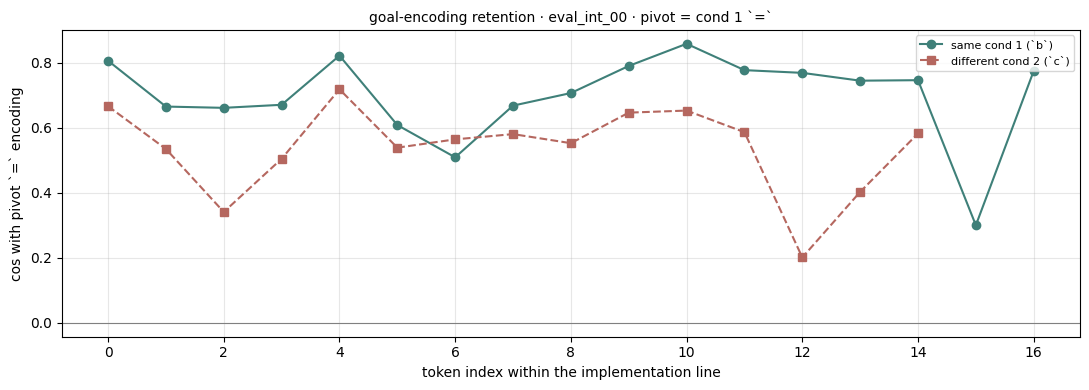

     per-token cosine with the pivot encoding     
┏━━━━┳━━━━━━━━━━━━┳━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━┓
┃  i ┃ same (`b`) ┃    cos ┃ diff (`c`) ┃    cos ┃
┡━━━━╇━━━━━━━━━━━━╇━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━┩
│  0 │ ' sum'     │ +0.807 │ ' sum'     │ +0.667 │
│  1 │ '(int'     │ +0.666 │ '(int'     │ +0.535 │
│  2 │ '(d'       │ +0.662 │ '(d'       │ +0.341 │
│  3 │ 'igit'     │ +0.671 │ 'igit'     │ +0.505 │
│  4 │ ')'        │ +0.822 │ ')'        │ +0.719 │
│  5 │ ' for'     │ +0.609 │ ' for'     │ +0.539 │
│  6 │ ' digit'   │ +0.509 │ ' digit'   │ +0.565 │
│  7 │ ' in'      │ +0.668 │ ' in'      │ +0.581 │
│  8 │ ' str'     │ +0.707 │ ' str'     │ +0.553 │
│  9 │ '(n'       │ +0.791 │ '(n'       │ +0.647 │
│ 10 │ '))'       │ +0.859 │ '))'       │ +0.653 │
│ 11 │ ' %'       │ +0.778 │ ' >'       │ +0.587 │
│ 12 │ ' '        │ +0.769 │ ' '        │ +0.201 │
│ 13 │ '9'        │ +0.745 │ '1'        │ +0.403 │
│ 14 │ ' =='      │ +0.747 │ '5'        │ +0.583 │
│ 15 │ ' '        │ +0.300 │            │        │
│ 16 │ '0'        │ +0.775 │            │        │
└────┴────────────┴────────┴────────────┴────────┘

mean cos — same: +0.699 | different: +0.538


In [7]:
PIVOT_K, OTHER_K = 1, 2          # pivot condition vs the contrast condition

def trajectory(anz, pivot_k, other_k):
    """cos(goal_enc(pivot `=`), goal_enc(t)) along pivot-impl (same) and other-impl (different)."""
    pk, ok = anz["conds"][pivot_k], anz["conds"][other_k]
    positions = [pk["eq"]] + pk["impl"] + ok["impl"]
    E = goal_encoding(anz["text"], positions)
    piv = E[0]
    same = [cos(piv, E[1 + i]) for i in range(len(pk["impl"]))]
    diff = [cos(piv, E[1 + len(pk["impl"]) + i]) for i in range(len(ok["impl"]))]
    return pk, ok, same, diff

pk, ok, same, diff = trajectory(EX, PIVOT_K, OTHER_K)
ids = prepare_input(prompts=EX["text"], tokenizer=mt).input_ids[0].tolist()
tok = lambda ps: [mt.tokenizer.decode([ids[p]]) for p in ps]

fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(range(len(same)), same, "o-", color="#3f8079", label=f"same cond {PIVOT_K} (`{pk['var']}`)")
ax.plot(range(len(diff)), diff, "s--", color="#b5675f", label=f"different cond {OTHER_K} (`{ok['var']}`)")
ax.axhline(0, color="grey", lw=0.8)
ax.set_xlabel("token index within the implementation line")
ax.set_ylabel("cos with pivot `=` encoding")
ax.set_title(f"goal-encoding retention · {EX['sample'].spec.spec_id} · pivot = cond {PIVOT_K} `=`", fontsize=10)
ax.grid(alpha=0.3); ax.legend(fontsize=8); plt.tight_layout(); plt.show()

t = Table(title="per-token cosine with the pivot encoding")
for c in ["i", f"same (`{pk['var']}`)", "cos", f"diff (`{ok['var']}`)", "cos"]:
    t.add_column(c, justify="right" if c in ("i", "cos") else "left")
for i in range(max(len(same), len(diff))):
    t.add_row(str(i),
              repr(tok(pk["impl"])[i]) if i < len(same) else "",
              f"{same[i]:+.3f}" if i < len(same) else "",
              repr(tok(ok["impl"])[i]) if i < len(diff) else "",
              f"{diff[i]:+.3f}" if i < len(diff) else "")
rich_print(t)
print(f"mean cos — same: {np.mean(same):+.3f} | different: {np.mean(diff):+.3f}")

### 1c. Cross-context: same predicate, different slot / different prompt

Build two prompts where the **same predicate** lands at a **different slot** (`b` vs `d`). Compare
the `=`-pivot encodings across contexts, against two baselines: the same-slot/different-predicate
pair, and a random different-predicate pair.

In [8]:
# ── §1c: same predicate, different context/slot. Corpus built the 12/12.1 way
# (ConditionSpec -> materialize), but with one predicate PINNED at a chosen slot. ──
from src.goals.condition_data import (INT_PREDICATES, ConditionSpec, materialize,
                                       sample_test_inputs)

_BY_ID = {p.id: p for p in INT_PREDICATES}
_SL = [p for p in INT_PREDICATES if p.has_singleline_for("python")]

def make_sample(pred_id, slot, n_conditions=5, seed=7):
    """A check_conditions(n) sample with `pred_id` pinned at `slot` (rest random).
    Builds ConditionSpec directly so predicate_ids / params / spec_texts stay in sync."""
    rng = random.Random(seed)
    others = [p for p in _SL if p.id != pred_id]
    chosen = rng.sample(others, n_conditions - 1)
    preds = chosen[:slot] + [_BY_ID[pred_id]] + chosen[slot:]
    params = [p.sample_params(rng) for p in preds]
    spec = ConditionSpec(
        spec_id=f"ret_{pred_id}_s{slot}_{seed}",
        predicate_ids=[p.id for p in preds],
        predicate_params=params,
        spec_texts=[p.render(pr) for p, pr in zip(preds, params)],
        id_substrs=[p.render_substrs(pr) for p, pr in zip(preds, params)],
        test_inputs=sample_test_inputs(rng, "int"),
    )
    return materialize([spec], langs=["python"], modularities=["monolithic"])[0]

def pivot_encoding_for(pred_id, slot, n_conditions=5, seed=7, span_source=SPAN_SOURCE):
    """(goal encoding at that predicate's `=`, analysis dict) — or (None, None)."""
    anz = analyze(make_sample(pred_id, slot, n_conditions, seed), span_source=span_source)
    if slot not in anz["conds"]:
        return None, None
    return goal_encoding(anz["text"], [anz["conds"][slot]["eq"]])[0], anz

PRED = "set_bits_gt"          # n has more than {t} ones in its binary representation
vb, _ = pivot_encoding_for(PRED, slot=1, seed=11)               # sits at `b`
vd, _ = pivot_encoding_for(PRED, slot=3, seed=29)               # sits at `d`, other context
vo, _ = pivot_encoding_for("digit_sum_gt", slot=1, seed=11)     # different pred, same slot
vo2, _ = pivot_encoding_for("palindrome", slot=3, seed=29)      # different pred, other context

t = Table(title=f"cross-context pivot-encoding similarity ({PRED})")
t.add_column("pair"); t.add_column("cos", justify="right")
if vb is not None and vd is not None: t.add_row("SAME pred, diff context+slot (b vs d)", f"{cos(vb, vd):+.3f}")
if vb is not None and vo is not None: t.add_row("diff pred, same slot (b)", f"{cos(vb, vo):+.3f}")
if vd is not None and vo2 is not None: t.add_row("diff pred, diff context (d)", f"{cos(vd, vo2):+.3f}")
rich_print(t)
rich_print("[grey58]retained goal => row 1 should sit clearly above rows 2-3[/grey58]")

     cross-context pivot-encoding similarity      
                  (set_bits_gt)                   
┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━┓
┃ pair                                  ┃    cos ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━┩
│ SAME pred, diff context+slot (b vs d) │ +0.869 │
│ diff pred, same slot (b)              │ +0.555 │
│ diff pred, diff context (d)           │ +0.383 │
└───────────────────────────────────────┴────────┘

retained goal => row 1 should sit clearly above rows 2-3

In [9]:
# test = pivot_encoding_for("digit_product_gt", slot=1, seed=11)

In [10]:
# test

## 2. Multi-step conditions — read-outs token by token  *(qualitative)*

Predicates with genuine sub-steps. `set_bits_gt` is the motivating case:

```
b = bin(abs(n)).count("1")     # step 1: to binary, count 1s
b = b > 2                      # step 2: threshold
```

For each token of the line we print the **faithfulness** (NL) and **causality** (C++) read-out, so
you can see whether the verbalization tracks the *current* sub-step and when the *next* condition
starts to appear.

In [11]:
from src.goals.goalscope import apply_goalscope

# both read-out flavours, matching scripts/evaluation/eval_goalscope.py
CAUSAL_PREFIX = "bool check(auto value){"
def build_causality_prompt():
    messages = [
        {"role": "system", "content": "You are a helpful assistant proficient in programming."},
        {"role": "user", "content": "You are implementing a simple C++ function that checks for a condition on an integer input. Just write the function body, without any comments or explanations. Assume all the necessary headers are already included."},
        {"role": "assistant", "content": CAUSAL_PREFIX},
    ]
    kw = dict(add_generation_prompt=False, continue_final_message=True, tokenize=False)
    try:
        return mt.tokenizer.apply_chat_template(messages, chat_template_kwargs={"enable_thinking": False}, **kw)
    except TypeError:
        return mt.tokenizer.apply_chat_template(messages, **kw)

GS = dict(selected_heads=goal_heads, strategy="additive", alpha=0.2,
          steer_layer_range=(35, 46), n_steer_tokens="all", max_new_tokens=64)

MULTISTEP_PREDS = ["set_bits_gt", "digit_product_gt", "digit_sum_divisible", "prime"]

def readout_table(anz, slot):
    """Per-token faithfulness + causality read-outs for the probed line."""
    s, text = anz["conds"][slot], anz["text"]
    positions = [s["eq"]] + s["impl"]
    ids = prepare_input(prompts=text, tokenizer=mt).input_ids[0].tolist()

    faith = {r["pos"]: r for r in apply_goalscope(text, mt=mt, show=False, include_noncode=False,
                                                  token_positions=positions, **GS)}
    causal = {r["pos"]: r for r in apply_goalscope(text, mt=mt, show=False, include_noncode=False,
                                                   token_positions=positions,
                                                   goalscope_prompt=build_causality_prompt(), **GS)}
    t = Table(box=SIMPLE_HEAVY, expand=True, pad_edge=False)
    t.add_column("token", no_wrap=True, style="bold", justify="right")
    t.add_column("F  (faithfulness / NL)", overflow="fold", style="sea_green3", ratio=1)
    t.add_column("C  (causality / C++)", overflow="fold", style="salmon1", ratio=1)
    for p in positions:
        tok = mt.tokenizer.decode([ids[p]])
        f = (faith.get(p, {}).get("patched_gen") or "").strip().replace("\n", " ↵\n")
        c = (causal.get(p, {}).get("patched_gen") or "").strip().replace("\n", " ↵\n")
        t.add_row(repr(tok), escape(f), escape(CAUSAL_PREFIX + c))
    return t


def show_predicate(pred_id, slot=1, n_conditions=4, seed=11, show_prompt=False,
                   span_source="oracle"):
    """ONE block per multi-step predicate: spec + LM implementation + identified segment,
    then that segment's per-token read-outs. Returns the analysis dict for further poking.

    span_source defaults to "oracle" here: rule_based_spans anchors on `^<letter> =`, so a
    temp variable in a multi-step impl (e.g. the loop var `d` in `for d in str(n): d = int(d)`)
    collides with condition letter `d` and truncates the segment. Multi-step predicates are
    exactly the case where that bites."""
    _, anz = pivot_encoding_for(pred_id, slot=slot, n_conditions=n_conditions, seed=seed,
                                span_source=span_source)
    if anz is None:
        rich_print(f"[red]could not place {pred_id} at slot {slot}[/red]"); return None
    rich_print(Panel(Group(context_render(anz, slot, show_prompt=show_prompt),
                           Text(""), readout_table(anz, slot)),
                     title=f"[bold]{pred_id}[/bold]  ·  slot {slot}  ·  seed {seed}",
                     title_align="left", border_style="cyan", padding=(1, 1)))
    return anz


# one block per multi-step predicate — run them one at a time and read each carefully
anz_setbits = show_predicate("digit_product_gt")

2026-07-30 17:32:06 src.utils.oracle_llms WARNING  temperature parameter is deprecated for claude-sonnet-5 - ignoring
2026-07-30 17:32:08 httpx INFO     HTTP Request: POST https://api.anthropic.com/v1/messages "HTTP/1.1 200 OK"


GoalScope[additive]:   0%|          | 0/3 [00:00<?, ?it/s]

The following generation flags are not valid and may be ignored: ['temperature', 'top_p', 'top_k']. Set `TRANSFORMERS_VERBOSITY=info` for more details.
You have set `compile_config`, but we are unable to meet the criteria for compilation. Compilation will be skipped.


GoalScope[additive]:   0%|          | 0/3 [00:00<?, ?it/s]

╭─ digit_product_gt  ·  slot 1  ·  seed 11 ───────────────────────────────────────────────────────────────────────╮
│                                                                                                                 │
│ ret_digit_product_gt_s1_11  preds=['power_of_two', 'digit_product_gt', 'digit_sum_divisible', 'digit_sum_gt']   │
│   a: n is a power of two                                                                                        │
│   b: the product of n's digits is greater than 5   <-- condition of interest                                    │
│   c: the sum of n's digits is divisible by 4                                                                    │
│   d: the sum of n's digits is greater than 20                                                                   │
│ ╭─ LM IMPLEMENTATION (greedy)  — yellow `=` pivot, cyan = probed segment ─────────────────────────────────────╮ │
│ │     a = (n & (n - 1) == 0) and n != 0                                                                       │ │
│ │     b = 1                                                                                                   │ │
│ │     s = 0                                                                                                   │ │
│ │     for d in str(n):                                                                                        │ │
│ │         d = int(d)                                                                                          │ │
│ │         b *= d                                                                                              │ │
│ │         s += d                                                                                              │ │
│ │     b = b > 5                                                                                               │ │
│ │     c = s % 4 == 0                                                                                          │ │
│ │     d = s > 20                                                                                              │ │
│ │     print(f"Condition 1: {a}, Condition 2: {b}, Condition 3: {c}, Condition 4: {d}, All conditions: {a and  │ │
│ │ b and c and d}")                                                                                            │ │
│ │ </code>                                                                                                     │ │
│ ╰─────────────────────────────────────────────────────────────────────────────────────────────────────────────╯ │
│ identified segment for `b` (cond 1): b = 1                                                                      │
│     s = 0                                                                                                       │
│     for d in str(n):                                                                                            │
│         d = int(d)                                                                                              │
│         b *= d                                                                                                  │
│         s += d                                                                                                  │
│     b = b > 5                                                                                                   │
│   eq@273 ' =' · impl tokens 274..313 (40): [' ', '1', '\n', '   ', ' s', ' =', ' ', '0', '\n', '   ', ' for', ' │
│ d', ' in', ' str', '(n', '):\n', '       ', ' d', ' =', ' int', '(d', ')\n', '       ', ' b', ' *=', ' d',      │
│ '\n', '       ', ' s', ' +=', ' d', '\n', '   ', ' b', ' =', ' b', ' >', ' ', '5', '\n']                        │
│                                                                                                                 │
│                                                                                                                 │
│      token   F  (faithfulness / NL)                   

In [12]:
seeds = [123, 29, 1123]
slots = [2, 1, 2]

for pred_id in MULTISTEP_PREDS:
    rich_print(f"\n[bold]predicate: [bright_yellow]{pred_id}[/bright_yellow][/bold]")
    for slot, seed in zip(slots, seeds):
        show_predicate(pred_id, slot=slot, n_conditions=4, seed=seed, show_prompt=False)

predicate: set_bits_gt

2026-07-30 17:33:39 src.utils.oracle_llms WARNING  temperature parameter is deprecated for claude-sonnet-5 - ignoring
2026-07-30 17:33:41 httpx INFO     HTTP Request: POST https://api.anthropic.com/v1/messages "HTTP/1.1 200 OK"


GoalScope[additive]:   0%|          | 0/1 [00:00<?, ?it/s]

GoalScope[additive]:   0%|          | 0/1 [00:00<?, ?it/s]

╭─ set_bits_gt  ·  slot 2  ·  seed 123 ───────────────────────────────────────────────────────────────────────────╮
│                                                                                                                 │
│ ret_set_bits_gt_s2_123  preds=['le_bound', 'perfect_cube', 'set_bits_gt', 'ge_bound']                           │
│   a: n is less than or equal to 500                                                                             │
│   b: n is a perfect cube                                                                                        │
│   c: n has more than 3 ones in its binary representation   <-- condition of interest                            │
│   d: n is greater than or equal to 0                                                                            │
│ ╭─ LM IMPLEMENTATION (greedy)  — yellow `=` pivot, cyan = probed segment ─────────────────────────────────────╮ │
│ │     a = n <= 500                                                                                            │ │
│ │     b = round(n ** (1/3)) ** 3 == n                                                                         │ │
│ │     c = bin(n).count('1') > 3                                                                               │ │
│ │     d = n >= 0                                                                                              │ │
│ │     print(f"Condition 1: {a}, Condition 2: {b}, Condition 3: {c}, Condition 4: {d}, All conditions: {a and  │ │
│ │ b and c and d}")                                                                                            │ │
│ │ </code>                                                                                                     │ │
│ ╰─────────────────────────────────────────────────────────────────────────────────────────────────────────────╯ │
│ identified segment for `c` (cond 2): c = bin(n).count('1') > 3                                                  │
│   eq@274 ' =' · impl tokens 275..285 (11): [' bin', '(n', ').', 'count', "('", '1', "')", ' >', ' ', '3', '\n'] │
│                                                                                                                 │
│                                                                                                                 │
│    token   F  (faithfulness / NL)                             C  (causality / C++)                              │
│  ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━  │
│     ' ='   I'm checking if the binary representation of a     bool check(auto value){return                     │
│            number has more than three '1's in its             std::bitset<sizeof(value)>(value).count('1') >    │
│            `bin(number).count('1') > 3`.                      3; }                                              │
│   ' bin'   I'm counting the number of '1's in the binary      bool check(auto value){return                     │
│            representation of the number and checking if       std::bitset<32>(value).count() > 5; }             │
│            it's greater than or equal to 5.                                                                     │
│     '(n'   I'm counting the number of '1's in the binary      bool check(auto value){return                     │
│            representation of the number and checking if it    bitset<32>(value).count() > 1 &&                  │
│            contains more than two '1's, then counting the     count(to_string(value).begin(),                   │
│            number of '1's in the binary representation and    to_string(value).end(), '1').substr().count('0')  │
│            comparing it to the string representation of the   - 1 > 0).count('1') - 1 > 0).count('0') > 3; }    │
│            number to count the number of '1's.                                                                  │
│     ').'   Counting the number of '1's in the binary  

2026-07-30 17:34:30 src.utils.oracle_llms WARNING  temperature parameter is deprecated for claude-sonnet-5 - ignoring
2026-07-30 17:34:34 httpx INFO     HTTP Request: POST https://api.anthropic.com/v1/messages "HTTP/1.1 200 OK"


... (42 outputs left out)

2026-07-30 17:44:14 src.utils.oracle_llms WARNING  temperature parameter is deprecated for claude-sonnet-5 - ignoring
2026-07-30 17:44:17 httpx INFO     HTTP Request: POST https://api.anthropic.com/v1/messages "HTTP/1.1 200 OK"


GoalScope[additive]:   0%|          | 0/2 [00:00<?, ?it/s]

GoalScope[additive]:   0%|          | 0/2 [00:00<?, ?it/s]

╭─ prime  ·  slot 2  ·  seed 1123 ────────────────────────────────────────────────────────────────────────────────╮
│                                                                                                                 │
│ ret_prime_s2_1123  preds=['perfect_cube', 'triangular', 'prime', 'digit_sum_divisible']                         │
│   a: n is a perfect cube                                                                                        │
│   b: n is a triangular number                                                                                   │
│   c: n is a prime number   <-- condition of interest                                                            │
│   d: the sum of n's digits is divisible by 3                                                                    │
│ ╭─ LM IMPLEMENTATION (greedy)  — yellow `=` pivot, cyan = probed segment ─────────────────────────────────────╮ │
│ │     a = round(n ** (1/3)) ** 3 == n                                                                         │ │
│ │     b = any(n == i * (i + 1) // 2 for i in range(1, n + 1))                                                 │ │
│ │     c = n > 1 and all(n % i != 0 for i in range(2, int(n ** 0.5) + 1))                                      │ │
│ │     d = sum(int(digit) for digit in str(n)) % 3 == 0                                                        │ │
│ │     print(f"Perfect cube: {a}, Triangular number: {b}, Prime number: {c}, Sum of digits divisible by 3:     │ │
│ │ {d}, All conditions: {a and b and c and d}")                                                                │ │
│ │ </code>                                                                                                     │ │
│ ╰─────────────────────────────────────────────────────────────────────────────────────────────────────────────╯ │
│ identified segment for `c` (cond 2): c = n > 1 and all(n % i != 0 for i in range(2, int(n ** 0.5) + 1))         │
│   eq@283 ' =' · impl tokens 284..314 (31): [' n', ' >', ' ', '1', ' and', ' all', '(n', ' %', ' i', ' !=', ' ', │
│ '0', ' for', ' i', ' in', ' range', '(', '2', ',', ' int', '(n', ' **', ' ', '0', '.', '5', ')', ' +', ' ',     │
│ '1', '))\n']                                                                                                    │
│                                                                                                                 │
│                                                                                                                 │
│     token   F  (faithfulness / NL)                            C  (causality / C++)                              │
│  ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━  │
│      ' ='   I'm checking if the current number is divisible   bool check(auto value){if(value < 2) return       │
│             by any number other than 1 and itself,            false; for(int i = 2; i <= sqrt(value); ++i)      │
│             indicating it's prime.                            if(value % i == 0) return false; return true; }   │
│      ' n'   I'm checking if the number is greater than 1      bool check(auto value){if(value < 2) return       │
│             and has no divisors other than 1 and itself       value > 1; for(int i = 2; i * i <= value; ++i)    │
│             (i.e., it is only divisible by 1 and itself).     if(value % i == 0) return false; return true; }   │
│             If the number is less than 2, it's not prime.                                                       │
│             For numbers greater than 2, it checks                                                               │
│             divisibility by all numbers                                                                         │
│      ' >'   I'm checking if the number is less than 2,        bool check(auto value){if(value < 2) return       │
│             returning false for numbers less than 2. T

### Notes / next steps

* §1 is **N=1** as sketched — if the same/different gap looks real, scale to many examples and plot
  mean ± CI (and add a *random-heads* control, as in `13_middle`).
* §1c currently reports single pairs; the honest version samples many (predicate, slot-pair) draws
  and compares the three distributions.
* A useful extra control for §1a: cosine against a **shuffled-token** baseline, to separate "goal
  retention" from "adjacent tokens are just similar".